In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import tiktoken
from torch.utils.data import Dataset, DataLoader

In [2]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}

In [3]:
class GPTDatasetv1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(
            txt,
            allowed_special={"<|endoftext|>"}
        )

        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1:i + max_length + 1]

            self.input_ids.append(
                torch.tensor(input_chunk, dtype=torch.long)
            )
            self.target_ids.append(
                torch.tensor(target_chunk, dtype=torch.long)
            )

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


In [4]:
def create_dataloader_v1(txt, batch_size=4, max_length=256, stride=128, shuffle=True, drop_last=True, num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetv1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last, num_workers=num_workers)
    return dataloader

In [5]:
# BPE Tokenization

tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Hello, I am a language model."
txt2 = "I am a really really helpful assistant."

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)


tensor([[15496,    11,   314,   716,   257,  3303,  2746,    13],
        [   40,   716,   257,  1107,  1107,  7613,  8796,    13]])


In [6]:
class LayerNorm(nn.Module): # done to solve the problem of exploding gradients and vanishing gradients
    def __init__(self, emb_dim, eps=1e-5):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(emb_dim))
        self.beta = nn.Parameter(torch.zeros(emb_dim))
        self.eps = eps

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        x_normalized = (x - mean) / torch.sqrt(var + self.eps)
        return self.gamma * x_normalized + self.beta

In [7]:
class GELU(nn.Module):
    def forward(self, x):
        return F.gelu(x)

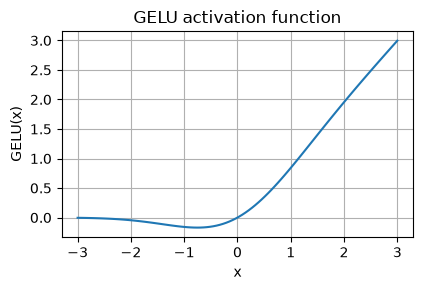

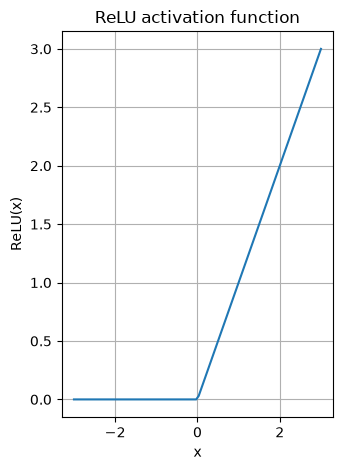

In [8]:
import matplotlib.pyplot as plt
gelu, relu = GELU(), nn.ReLU()
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)
plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [9]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )
    def forward(self, x):
        return self.layers(x)

In [10]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut=False):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), nn.GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), nn.GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), nn.GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), nn.GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), nn.GELU())
        ])

    def forward(self, x):
        for layer in self.layers:
            layer_output = layer(x)
            if self.use_shortcut and layer_output.shape == x.shape:
                x = x + layer_output  # Add shortcut connection
            else:
                x = layer_output
        return x

def print_gradients(model, x):
    output = model(x)
    target = torch.tensor([[0.0]])
    loss = nn.MSELoss()
    loss = loss(output, target)
    loss.backward()
    for name, param in model.named_parameters():
        if 'weight' in name:
            print(f"Gradients for {name}: {param.grad.abs().mean().item()}")


In [11]:
layer_sizes = [3, 3, 3, 3, 3, 1]
sample_input = torch.tensor([[-1., 0., 1.]])
torch.manual_seed(123)
model_no_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=False)
print("Model without shortcut connections:")
print_gradients(model_no_shortcut, sample_input)

Model without shortcut connections:
Gradients for layers.0.0.weight: 0.00025463770725764334
Gradients for layers.1.0.weight: 8.308836549986154e-05
Gradients for layers.2.0.weight: 0.0007468733238056302
Gradients for layers.3.0.weight: 0.0012376185040920973
Gradients for layers.4.0.weight: 0.004640504717826843


In [12]:
model_with_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=True)
print("\nModel with shortcut connections:")
print_gradients(model_with_shortcut, sample_input)
#proved that shorcit connections help in preventing vanishing gradients and exploding gradients.


Model with shortcut connections:
Gradients for layers.0.0.weight: 0.0033791481982916594
Gradients for layers.1.0.weight: 0.003010491142049432
Gradients for layers.2.0.weight: 0.0008663078770041466
Gradients for layers.3.0.weight: 0.004077323712408543
Gradients for layers.4.0.weight: 0.0309309009462595


In [13]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.qkv_bias = qkv_bias
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, _ = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        keys = keys.transpose(1, 2)
        values = values.transpose(1, 2)
        queries = queries.transpose(1, 2)

        attn_scores = queries @ keys.transpose(-2, -1)
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        attn_scores = attn_scores.masked_fill(mask_bool, float('-inf'))

        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = (attn_weights @ values).transpose(1, 2)
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)

        return self.out_proj(context_vec)


In [14]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            dropout=cfg["drop_rate"],
            num_heads=cfg["n_heads"],
            qkv_bias=cfg["qkv_bias"]
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):   
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x


In [15]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()

        self.token_emb = nn.Embedding(
            cfg["vocab_size"], cfg["emb_dim"]
        )

        self.pos_emb = nn.Embedding(
            cfg["context_length"], cfg["emb_dim"]
        )

        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[
                TransformerBlock(cfg)
                for _ in range(cfg["n_layers"])
            ]
        )

        self.final_norm = LayerNorm(cfg["emb_dim"])

        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.size()

        tok_embeds = self.token_emb(in_idx)

        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)
        )

        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)

        logits = self.out_head(x)

        return logits

In [16]:
def generate_text(model, idx, max_length=50, context_length=1024):
    device = next(model.parameters()).device
    idx = idx.to(device)
    for _ in range(max_length):
        idx_cond = idx[:, -context_length:]
        with torch.no_grad():
            logits = model(idx_cond)

        logits = logits[:, -1, :]
        probs = torch.softmax(logits, dim=-1)
        idx_next = torch.argmax(probs, dim=-1, keepdim=True)
        idx = torch.cat((idx, idx_next), dim=1)
        
        
    return idx

In [17]:
start_context = "Hello, I am"
encoded_context = tokenizer.encode(start_context)
print("Encoded context:", encoded_context)

encoded_context_tensor = torch.tensor([encoded_context], dtype=torch.long)
print("Encoded context tensor shape:", encoded_context_tensor.shape)
model = GPTModel(GPT_CONFIG_124M)

Encoded context: [15496, 11, 314, 716]
Encoded context tensor shape: torch.Size([1, 4])


In [18]:
out = generate_text(model, encoded_context_tensor, max_length=6, context_length=GPT_CONFIG_124M["context_length"])
tokenizer.decode(out[0].tolist()) 
# the output comes out as junk cuz we are not doing any training yet. The model is untrained and will produce random outputs.

'Hello, I amcape curb sauces Cherokee maximumarie'

### Training and Evaluating

In [19]:
model.eval();

def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text)
    encoded_tensor = torch.tensor([encoded], dtype=torch.long)
    return encoded_tensor

In [20]:
start_context = "Hello, I am"
tokenizer = tiktoken.get_encoding("gpt2")
text_tensor = text_to_token_ids(start_context, tokenizer)
text_tensor

tensor([[15496,    11,   314,   716]])

In [21]:
def token_ids_to_text(token_ids, tokenizer):
    decoded_text = tokenizer.decode(token_ids.squeeze(0).tolist())
    return decoded_text

In [22]:
token_ids_to_text(text_tensor, tokenizer)

'Hello, I am'

In [23]:
token_ids = generate_text(model, text_tensor, max_length=1, context_length=GPT_CONFIG_124M["context_length"])

In [24]:
token_ids.squeeze(0).shape

torch.Size([5])

In [25]:
token_ids_to_text(token_ids.squeeze(0), tokenizer)

'Hello, I am chained'

In [26]:
file_path = "shakespeare.txt"
with open(file_path, "r", encoding="utf-8") as f:
    text_data = f.read()

total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))
print("Characters:", total_characters)
print("Tokens:", total_tokens)

Characters: 1115394
Tokens: 338025


In [27]:
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

In [28]:
train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [29]:
print("Train loader:")
for x, y in train_loader:
    print(x.shape, y.shape)
print("\nValidation loader:")
for x, y in val_loader:
    print(x.shape, y.shape)

Train loader:
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 1024]) torch.Size([2, 1024])
torch.Size([2, 102

In [30]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(
    logits.flatten(0, 1), target_batch.flatten()
    )
    return loss

def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(
            input_batch, target_batch, model, device
            )
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches 

In [31]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device)
    val_loss = calc_loss_loader(val_loader, model, device)
print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 10.9530229049475
Validation loss: 10.945796754625109


In [32]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(
            train_loader, model, device, num_batches=eval_iter
        )
        val_loss = calc_loss_loader(
            val_loader, model, device, num_batches=eval_iter
        )
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_length = model.pos_emb.weight.shape[0]

    encoded = text_to_token_ids(start_context, tokenizer).to(device)

    with torch.no_grad():
        token_ids = generate_text(
            model=model,
            idx=encoded,
            max_length=50,
            context_length=context_length
        )

    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))

    model.train()

In [33]:
def train_model_simple(model, train_loader, val_loader,
    optimizer, device, num_epochs,
    eval_freq, eval_iter, start_context, tokenizer):
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1
    for epoch in range(num_epochs):
        model.train()
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()
            loss = calc_loss_batch(
                input_batch, target_batch, model, device
            )
            loss.backward()
            optimizer.step()
            tokens_seen += input_batch.numel()
            global_step += 1
            
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                        f"Train loss {train_loss:.3f}, "
                        f"Val loss {val_loss:.3f}"
                )
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )
    return train_losses, val_losses, track_tokens_seen

In [34]:
RUN_TRAINING = False
CHECKPOINT_PATH = "gpt2_model.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = GPTModel(GPT_CONFIG_124M).to(device)

if RUN_TRAINING:
    torch.manual_seed(123)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.0004,
        weight_decay=0.1
    )
    num_epochs = 10
    train_losses, val_losses, tokens_seen = train_model_simple(
        model, train_loader, val_loader, optimizer, device,
        num_epochs=num_epochs,
        eval_freq=5,
        eval_iter=5,
        start_context="Every effort moves you",
        tokenizer=tokenizer
    )
    torch.save(model.state_dict(), CHECKPOINT_PATH)
    print(f"Saved trained model to {CHECKPOINT_PATH}")
else:
    model.load_state_dict(torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=True
    ))
    print(f"Loaded model from {CHECKPOINT_PATH}; training skipped.")

Loaded model from gpt2_model.pth; training skipped.


In [35]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(
    epochs_seen, val_losses, linestyle="-.", label="Validation loss"
    )
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax2 = ax1.twiny()
    ax2.plot(tokens_seen, train_losses, alpha=0)
    ax2.set_xlabel("Tokens seen")
    fig.tight_layout()
    plt.show()


if RUN_TRAINING:
    epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
    plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)
else:
    print("Loss plot skipped because training was skipped.")

Loss plot skipped because training was skipped.


In [36]:
model.to(device)
model.eval();

tokenizer = tiktoken.get_encoding("gpt2")
token_ids = generate_text(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_length=25,
    context_length=GPT_CONFIG_124M["context_length"]
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you are past of these are near in them;
And shall the or fortune cast'd,
And startled,
enforce


In [37]:
#k sampling and temperature scaling
def generate(model, idx, max_length=50, context_length=1024, temperature=1.0, top_k=None, eos_idx=None):
    device = next(model.parameters()).device
    idx = idx.to(device)
    for _ in range(max_length):
        idx_cond = idx[:, -context_length:]
        with torch.no_grad():
            logits = model(idx_cond)

        logits = logits[:, -1, :]

        if top_k is not None:
            top_logits, top_pos = torch.topk(logits, top_k, dim=-1)
            new_logits = torch.where(
                condition=logits < top_logits[:, -1, None],
                input = torch.full_like(logits, float('-inf')),
                other = logits
            )
            logits = new_logits

        probs = torch.softmax(logits, dim=-1)

        if temperature >0.0:
            logits = logits / temperature
            probs = torch.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
        else:
            idx_next = torch.argmax(probs, dim=-1, keepdim=True)
        
        if idx_next.item() == eos_idx:
            break
        idx = torch.cat((idx, idx_next), dim=1)
        
        
    return idx

In [38]:
token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_length=25,
    context_length=GPT_CONFIG_124M["context_length"],
    temperature=0.7,
    top_k=5
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you have we proceed that I have a bond

And shall the or fortune and with his highness' soldiers;
Th


In [39]:
from gpt_download import download_and_load_gpt2

settings, params = download_and_load_gpt2("124M", models_dir = "gpt2")

File already exists and is up-to-date: gpt2\124M\checkpoint
File already exists and is up-to-date: gpt2\124M\encoder.json
File already exists and is up-to-date: gpt2\124M\hparams.json
File already exists and is up-to-date: gpt2\124M\model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2\124M\model.ckpt.index
File already exists and is up-to-date: gpt2\124M\model.ckpt.meta
File already exists and is up-to-date: gpt2\124M\vocab.bpe


In [40]:
# Define model configurations in a dictionary for compactness
model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

# Copy the base configuration and update with specific model settings
model_name = "gpt2-small (124M)"  # Example model name
NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])
NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})

gpt = GPTModel(NEW_CONFIG)
gpt.eval();

In [41]:
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(torch.tensor(right))

In [42]:
import numpy as np

def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params['wpe'])
    gpt.token_emb.weight = assign(gpt.token_emb.weight, params['wte'])
    
    for b in range(len(params["blocks"])):
        q_w, k_w, v_w = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight, 
            params["blocks"][b]["attn"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias, 
            params["blocks"][b]["attn"]["c_proj"]["b"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight, 
            params["blocks"][b]["mlp"]["c_fc"]["w"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias, 
            params["blocks"][b]["mlp"]["c_fc"]["b"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight, 
            params["blocks"][b]["mlp"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias, 
            params["blocks"][b]["mlp"]["c_proj"]["b"])

        gpt.trf_blocks[b].norm1.gamma = assign(
            gpt.trf_blocks[b].norm1.gamma, 
            params["blocks"][b]["ln_1"]["g"])
        gpt.trf_blocks[b].norm1.beta = assign(
            gpt.trf_blocks[b].norm1.beta, 
            params["blocks"][b]["ln_1"]["b"])
        gpt.trf_blocks[b].norm2.gamma = assign(
            gpt.trf_blocks[b].norm2.gamma, 
            params["blocks"][b]["ln_2"]["g"])
        gpt.trf_blocks[b].norm2.beta = assign(
            gpt.trf_blocks[b].norm2.beta, 
            params["blocks"][b]["ln_2"]["b"])

    gpt.final_norm.gamma = assign(gpt.final_norm.gamma, params["g"])
    gpt.final_norm.beta = assign(gpt.final_norm.beta, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])
    
    
load_weights_into_gpt(gpt, params)
gpt.to(device);

In [44]:
# torch.manual_seed(123)

token_ids = generate(
    model=gpt,
    idx=text_to_token_ids("I love Anish and Anugnya", tokenizer),
    max_length=90,
    context_length=NEW_CONFIG["context_length"],
    temperature=0.7,
    top_k=25
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 I love Anish and Anugnya, too. They are both wonderful actors to work with. I love how much they care about their characters' lives and how they treat each other.

The story takes place on an island between two worlds. The first world is the world of the human race, and the second is the world of the elves. But the human race is also divided into two worlds that are also connected. The human race is divided into two worlds, and they
